<a href="https://colab.research.google.com/github/sumin031130/ESAA/blob/main/ESAA_%EA%B5%B0%EC%A7%91%ED%99%941_2_ch7_1_4_%EC%BD%94%EB%93%9C%EC%88%98%EC%A0%95%EB%B3%B8.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# 07 군집화
## 01 K-평균 알고리즘 이해

- K-평균은 군집화(Clustering)에서 가장 일반적으로 사용되는 알고리즘임
- 군집 중심점(centroid)이라는 특정한 임의의 지점을 선택해 해당 중심에 가장 가까운 포인트들을 선택하는 군집화 기법임
- 군집 중심점은 선택된 포인트의 평균 지점으로 이동 → 이동된 중심점에서 다시 가까운 포인트 선택 → 다시 평균 지점으로 이동하는 프로세스를 반복
- 모든 데이터 포인트에서 더 이상 중심점의 이동이 없을 경우 반복을 멈추고 해당 중심점에 속하는 데이터 포인트들을 군집화함

**K-평균 동작 과정 **
1. 군집화의 기준이 되는 중심을 군집화할 개수만큼 임의의 위치에 가져다 놓음 (2개로 군집화하려면 2개의 중심을 임의 위치에 둠)
2. 각 데이터는 가장 가까운 곳에 위치한 중심점에 소속됨 (A, B → 같은 중심점 / C, E, F → 같은 중심점)
3. 소속이 결정되면 군집 중심점을 소속된 데이터의 평균 중심으로 이동 (A, B의 평균 위치로, C, E, F의 평균 위치로)
4. 각 데이터는 기존에 속한 중심점보다 더 가까운 중심점이 있다면 해당 중심점으로 다시 소속 변경 (C 데이터가 더 가까운 중심점으로 변경)
5. 다시 중심을 소속된 데이터의 평균 중심으로 이동 (C의 소속 변경으로 두 개의 중심 모두 이동)
6. 중심점을 이동했는데 데이터의 중심점 소속 변경이 없으면 군집화 종료. 그렇지 않으면 4번 과정을 거쳐 소속을 변경하고 이 과정 반복

**K-평균의 장점**
- 일반적인 군집화에서 가장 많이 활용되는 알고리즘임
- 알고리즘이 쉽고 간결함

**K-평균의 단점**
- 거리 기반 알고리즘으로 속성의 개수가 매우 많을 경우 군집화 정확도가 떨어짐 (이를 위해 PCA로 차원 감소를 적용해야 할 수도 있음)
- 반복을 수행하는데, 반복 횟수가 많을 경우 수행 시간이 매우 느려짐
- 몇 개의 군집(cluster)을 선택해야 할지 가이드하기가 어려움

### 사이킷런 KMeans 클래스 소개

- 사이킷런은 K-평균 구현을 위해 `KMeans` 클래스를 제공함. 초기화 파라미터는 다음과 같음

In [1]:
# class sklearn.cluster.KMeans(n_clusters=8, init='k-means++', n_init=10, max_iter=300, tol=0.0001,
#                              precompute_distances='auto', verbose=0, random_state=None,
#                              copy_x=True, n_jobs=1, algorithm='auto')

- 중요한 파라미터
  - `n_clusters`: KMeans 초기화 파라미터 중 가장 중요. 군집화할 개수, 즉 군집 중심점의 개수
  - `init`: 초기에 군집 중심점의 좌표를 설정할 방식. 보통 임의로 설정하지 않고 일반적으로 k-means++ 방식으로 최초 설정
  - `max_iter`: 최대 반복 횟수. 이 횟수 이전에 모든 데이터의 중심점 이동이 없으면 종료
- KMeans는 사이킷런의 비지도학습 클래스와 마찬가지로 `fit(데이터 세트)` 또는 `fit_transform(데이터 세트)` 메서드로 수행
- 수행된 KMeans 객체의 주요 속성
  - `labels_`: 각 데이터 포인트가 속한 군집 중심점 레이블
  - `cluster_centers_`: 각 군집 중심점 좌표(Shape는 [군집 개수, 피처 개수]). 이를 이용하면 군집 중심점 좌표가 어디인지 시각화 가능

### K-평균을 이용한 붓꽃 데이터 세트 군집화

- 붓꽃 데이터(꽃받침(sepal)과 꽃잎(petal)의 길이와 너비에 따른 품종 분류 데이터 세트)를 이용해 K-평균 군집화 수행
- 꽃받침, 꽃잎의 길이에 따라 각 데이터의 군집화가 어떻게 결정되는지 확인하고, 이를 분류 값과 비교

In [2]:
from sklearn.preprocessing import scale
from sklearn.datasets import load_iris
from sklearn.cluster import KMeans
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
%matplotlib inline

iris = load_iris()
# 더 편리한 데이터 핸들링을 위해 DataFrame으로 변환
irisDF = pd.DataFrame(data=iris.data, columns=['sepal_length', 'sepal_width', 'petal_length',
'petal_width'])
irisDF.head(3)

,sepal_length,sepal_width,petal_length,petal_width
0,5.1,3.5,1.4,0.2
1,4.9,3.0,1.4,0.2
2,4.7,3.2,1.3,0.2


- 붓꽃 데이터 세트를 3개 그룹으로 군집화 → `n_cluster`는 3, 초기 중심 설정 방식은 디폴트 값인 k-means++, 최대 반복 횟수 역시 디폴트 값인 max_iter=300으로 설정한 KMeans 객체를 만들고 `fit()` 수행

In [3]:
kmeans = KMeans(n_clusters=3, init='k-means++', max_iter=300,random_state=0)
kmeans.fit(irisDF)

KMeans(n_clusters=3, random_state=0)

- `fit()` 수행 결과가 kmeans 객체 변수로 반환됨. `labels_` 속성값으로 irisDF의 각 데이터가 어떤 중심에 속하는지 확인 가능

In [4]:
print(kmeans.labels_)

[1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1
 1 1 1 1 1 1 1 1 1 1 1 1 1 2 0 2 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0
 0 0 0 2 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 2 0 2 2 2 2 0 2 2 2 2
 2 2 0 0 2 2 2 2 0 2 0 2 0 2 2 0 0 2 2 2 2 2 0 2 2 2 2 0 2 2 2 0 2 2 2 0 2
 2 0]


- labels_의 값이 0, 1, 2로 돼 있으며, 각 레코드가 첫 번째, 두 번째, 세 번째 군집에 속함을 의미함
- 실제 붓꽃 품종 분류 값과 비교: target 값을 'target' 칼럼으로, labels_ 값을 'cluster' 칼럼으로 irisDF에 추가한 뒤 group by 연산으로 target과 cluster 값 개수 비교

In [5]:
irisDF['target'] = iris.target
irisDF['cluster']=kmeans.labels_
iris_result = irisDF.groupby(['target','cluster'])['sepal_length'].count()
print(iris_result)

target  cluster
0       1          50
1       0          47
        2           3
2       0          14
        2          36
Name: sepal_length, dtype: int64


- 분류 타깃 0값 데이터는 1번 군집으로 모두 잘 그루핑됨
- Target 1 값 데이터는 2개만 2번 군집, 나머지 48개는 모두 0번 군집으로 그루핑됨
- Target 2 값 데이터는 0번 군집에 14개, 2번 군집에 36개로 분산돼 그루핑됨
- 군집화 시각화: 붓꽃 속성이 4개이므로 2차원 평면에 적합하지 않아 PCA로 4개 속성을 2개로 차원 축소한 뒤 X 좌표, Y 좌표로 개별 데이터 표현

In [6]:
from sklearn.decomposition import PCA

pca = PCA(n_components=2)
pca_transformed = pca.fit_transform(iris.data)

irisDF['pca_x'] = pca_transformed[:, 0]
irisDF['pca_y'] = pca_transformed[:, 1]
irisDF.head(3)

,sepal_length,sepal_width,petal_length,petal_width,target,cluster,pca_x,pca_y
0,5.1,3.5,1.4,0.2,0,1,-2.684126,0.319397
1,4.9,3.0,1.4,0.2,0,1,-2.714142,-0.177001
2,4.7,3.2,1.3,0.2,0,1,-2.888991,-0.144949


- pca_x는 X 좌표 값, pca_y는 Y 좌표 값
- 군집별로 cluster 0은 마커 'o', cluster 1은 마커 's', cluster 2는 마커 '^'로 표현

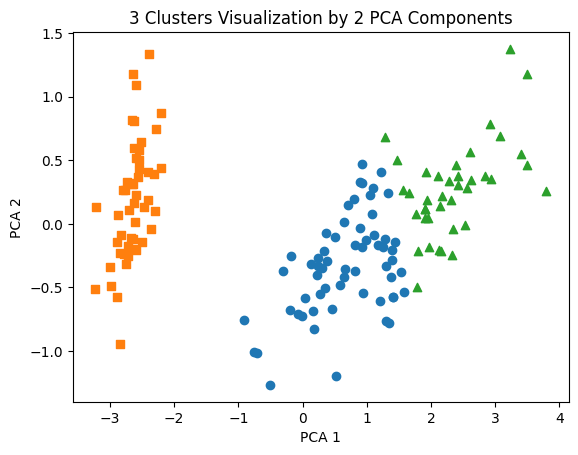

In [8]:
# 군집 값이 0, 1, 2인 경우마다 별도의 인덱스로 추출
marker0_ind = irisDF[irisDF['cluster']==0].index
marker1_ind = irisDF[irisDF['cluster']==1].index
marker2_ind = irisDF[irisDF['cluster']==2].index

# 군집 값 0, 1, 2에 해당하는 인덱스로 각 군집 레벨의 pca_x, pca_y 값 추출. o, s, ^ 로 마커 표시
plt.scatter(x=irisDF.loc[marker0_ind, 'pca_x'], y=irisDF.loc[marker0_ind, 'pca_y'], marker='o')
plt.scatter(x=irisDF.loc[marker1_ind, 'pca_x'], y=irisDF.loc[marker1_ind, 'pca_y'], marker='s')
plt.scatter(x=irisDF.loc[marker2_ind, 'pca_x'], y=irisDF.loc[marker2_ind, 'pca_y'], marker='^')

plt.xlabel('PCA 1')
plt.ylabel('PCA 2')
plt.title('3 Clusters Visualization by 2 PCA Components')
plt.show()

- Cluster 1을 나타내는 네모(square, 's')는 명확히 다른 군집과 잘 분리돼 있음
- Cluster 0을 나타내는 동그라미('o')와 Cluster 2를 나타내는 세모('^')는 상당 수준 분리돼 있지만, 네모만큼 명확하게 분리돼 있지는 않음
- Cluster 0과 1의 경우 속성의 위치 자체가 명확히 분리되기 어려운 부분이 존재함

### 군집화 알고리즘 테스트를 위한 데이터 생성

- 사이킷런은 군집화 알고리즘 테스트용 간단한 데이터 생성기 제공: 대표적으로 `make_blobs()`, `make_classification()` API
- 두 API 모두 여러 개의 클래스에 해당하는 데이터 세트를 만들고, 하나의 클래스에 여러 개의 군집이 분포될 수 있게 데이터 생성 가능
  - `make_blobs()`: 개별 군집의 중심점과 표준 편차 제어 기능이 추가돼 있음
  - `make_classification()`: 노이즈를 포함한 데이터를 만드는 데 유용
  - 둘 다 분류 용도로도 테스트 데이터 생성 가능
- 이 외에 `make_circle()`, `make_moon()` API는 중심 기반의 군집화로 해결하기 어려운 데이터 세트를 만드는 데 사용
- `make_blobs()`는 피처 데이터 세트와 타깃 데이터 세트가 튜플(Tuple)로 반환됨. 호출 파라미터:
  - `n_samples`: 생성할 총 데이터의 개수. 디폴트는 100개
  - `n_features`: 데이터의 피처 개수. 시각화가 목표면 2개로 설정해 첫 번째 피처는 x 좌표, 두 번째 피처는 y 좌표상에 표현
  - `centers`: int 값(예: 3)이면 군집의 개수, ndarray 형태면 개별 군집 중심점의 좌표
  - `cluster_std`: 생성될 군집 데이터의 표준 편차. float 값 0.8이면 군집 내 데이터가 표준편차 0.8을 가진 값으로 만들어짐. [0.8, 1.2, 0.6]처럼 표현되면 3개 군집에서 첫 번째 군집 내 표준편차 0.8, 두 번째 1.2, 세 번째 0.6으로 만듦 → 군집별로 서로 다른 표준 편차를 가진 데이터 세트를 만들 때 사용
- `X, y = make_blobs(n_samples=200, n_features=2, centers=3, random_state=0)` 호출 시 총 200개의 레코드와 2개의 피처가 3개의 군집화 기반 분포도를 가진 피처 데이터 세트 X와, 3개의 군집화 값을 가진 타깃 데이터 세트 y가 반환됨

In [9]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.cluster import KMeans
from sklearn.datasets import make_blobs
%matplotlib inline

X, y = make_blobs(n_samples=200, n_features=2, centers=3, cluster_std=0.8, random_state=0)
print(X.shape, y.shape)

# y target 값의 분포를 확인
unique, counts = np.unique(y, return_counts=True)
print(unique, counts)

(200, 2) (200,)
[0 1 2] [67 67 66]


- 피처 데이터 세트 X는 200개의 레코드와 2개의 피처 → shape (200, 2), 군집 타깃 데이터 세트 y의 shape은 (200,)
- 3개의 cluster 값은 [0, 1, 2]이며 각각 67, 67, 66개로 균일하게 구성됨
- 데이터 가공 편의를 위해 DataFrame으로 변경. 피처 이름은 ftr1, ftr2

In [10]:
import pandas as pd

clusterDF = pd.DataFrame(data=X, columns=['ftr1', 'ftr2'])
clusterDF['target'] = y
clusterDF.head(3)

,ftr1,ftr2,target
0,-1.692427,3.622025,2
1,0.697940,4.428867,0
2,1.100228,4.606317,0


- 타깃값 0, 1, 2에 따라 마커를 다르게 해서 산점도를 그리면 3개의 구분될 수 있는 군집 영역(make_blobs()의 y 반환 값)으로 피처 데이터 세트가 만들어졌음을 알 수 있음

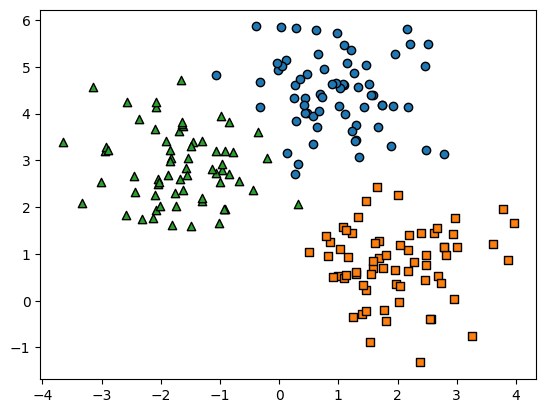

In [11]:
target_list = np.unique(y)
# 각 타깃별 산점도의 마커 값.
markers=['o', 's', '^', 'P', 'D', 'H', 'x']
# 3개의 군집 영역으로 구분한 데이터 세트를 생성했으므로 target_list는 [0, 1, 2]
# target==0, target==1, target==2 로 scatter plot을 marker별로 생성.
for target in target_list:
    target_cluster = clusterDF[clusterDF['target']==target]
    plt.scatter(x=target_cluster['ftr1'], y=target_cluster['ftr2'], edgecolor='k',
                marker=markers[target] )
plt.show()

- 만들어진 데이터 세트에 KMeans 군집화 수행 후 군집별 시각화
- KMeans 객체에 `fit_predict(X)`를 수행해 make_blobs()의 피처 데이터 세트인 X 데이터를 군집화 → clusterDF의 'kmeans_label' 칼럼으로 저장
- KMeans 객체의 `cluster_centers_` 속성은 개별 군집의 중심 위치 좌표를 나타내기 위해 사용

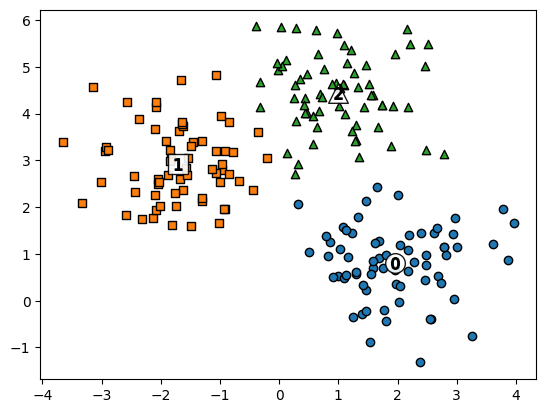

In [12]:
# KMeans 객체를 이용해 X 데이터를 K-Means 클러스터링 수행
kmeans = KMeans(n_clusters=3, init='k-means++', max_iter=200, random_state=0)
cluster_labels = kmeans.fit_predict(X)
clusterDF['kmeans_label']  = cluster_labels

# cluster_centers_ 는 개별 클러스터의 중심 위치 좌표 시각화를 위해 추출
centers = kmeans.cluster_centers_
unique_labels = np.unique(cluster_labels)
markers=['o', 's', '^', 'P', 'D', 'H', 'x']

# 군집된 label 유형별로 iteration 하면서 marker 별로 scatter plot 수행.
for label in unique_labels:
    label_cluster = clusterDF[clusterDF['kmeans_label']==label]
    center_x_y = centers[label]
    plt.scatter(x=label_cluster['ftr1'], y=label_cluster['ftr2'], edgecolor='k',
                marker=markers[label] )

    # 군집별 중심 위치 좌표 시각화
    plt.scatter(x=center_x_y[0], y=center_x_y[1], s=200, color='white',
                alpha=0.9, edgecolor='k', marker=markers[label])
    plt.scatter(x=center_x_y[0], y=center_x_y[1], s=70, color='k', edgecolor='k',
                marker='$%d$' % label)

plt.show()

- make_blobs()의 타깃과 kmeans_label은 군집 번호를 의미하므로 서로 다른 값으로 매핑될 수 있음 (그래서 산점도의 마커가 서로 다를 수 있음)

In [13]:
print(clusterDF.groupby('target')['kmeans_label'].value_counts())

target  kmeans_label
0       2               66
        1                1
1       0               67
2       1               65
        0                1
Name: count, dtype: int64


- Target 0이 cluster label 0으로, target 1이 label 2로, target 2가 label 1로 거의 대부분 잘 매핑됨
- make_blobs()은 `cluster_std` 파라미터로 데이터의 분포도를 조절함
- 그림: cluster_std가 0.4, 0.8, 1.2, 1.6일 때의 데이터 시각화 → cluster_std가 작을수록 군집 중심에 데이터가 모여 있으며, 클수록 데이터가 퍼져 있음 (책에 그림만 있고 코드는 없음)

## 02 군집 평가(Cluster Evaluation)

- 붓꽃 데이터 세트는 결괏값에 품종을 뜻하는 타깃 레이블이 있어 군집화 결과를 비교해 효율성을 짐작할 수 있었음
- 하지만 대부분의 군집화 데이터 세트는 비교할 만한 타깃 레이블이 없음
- 군집화는 분류(Classification)와 유사해 보일 수 있으나 성격이 많이 다름: 데이터 내에 숨어 있는 별도의 그룹을 찾아 의미를 부여하거나, 동일한 분류 값에 속하더라도 그 안에서 더 세분화된 군집화를 추구하거나, 서로 다른 분류 값의 데이터도 더 넓은 군집화 레벨화 등의 영역을 가짐
- 비지도학습의 특성상 어떠한 지표라도 정확하게 성능을 평가하기는 어려움 → 군집화 성능 평가의 대표적인 방법으로 **실루엣 분석** 이용

### 실루엣 분석의 개요

- 실루엣 분석(silhouette analysis): 각 군집 간의 거리가 얼마나 효율적으로 분리돼 있는지를 나타냄
  - 효율적으로 잘 분리됨 = 다른 군집과의 거리는 떨어져 있고 동일 군집끼리의 데이터는 서로 가깝게 잘 뭉쳐 있음
  - 군집화가 잘 될수록 개별 군집은 비슷한 정도의 여유공간을 가지고 떨어져 있음
- 실루엣 분석은 **실루엣 계수(silhouette coefficient)** 를 기반으로 함
  - 실루엣 계수: 개별 데이터가 가지는 군집화 지표. 해당 데이터가 같은 군집 내의 데이터와 얼마나 가깝게 군집화돼 있고, 다른 군집에 있는 데이터와는 얼마나 멀리 분리돼 있는지를 나타냄
- 그림 설명
  - a<sub>ij</sub>: i번째 데이터에서 자신이 속한 클러스터 내의 다른 데이터 포인트까지의 거리 (a12: 1번 데이터에서 2번 데이터까지의 거리)
  - a(i): i번째 데이터에서 자신이 속한 클러스터 내의 다른 데이터 포인트들의 평균 거리 (a(i) = 평균(a12, a13, a13))
  - b(i): i번째 데이터에서 가장 가까운 타 클러스터 내의 다른 데이터 포인트들의 평균 거리 (b(i) = 평균(b15, b16, b17, b18))
- 두 군집 간의 거리가 얼마나 떨어져 있는가의 값은 b(i) − a(i)이며, 이를 정규화하기 위해 MAX(a(i), b(i)) 값으로 나눔

$$ s(i) = \frac{(b(i) - a(i))}{(\max(a(i), b(i)))} $$

- 실루엣 계수는 −1에서 1 사이의 값
  - 1로 가까워질수록 근처의 군집과 더 멀리 떨어져 있음
  - 0에 가까울수록 근처의 군집과 가까워짐
  - − 값은 아예 다른 군집에 데이터 포인트가 할당됐음을 뜻함
- 사이킷런 실루엣 분석 메서드
  - `sklearn.metrics.silhouette_samples(X, labels, metric='euclidean', **kwds)`: X feature 데이터 세트와 각 피처 데이터 세트가 속한 군집 레이블 값인 labels 데이터를 입력하면 각 데이터 포인트의 실루엣 계수를 계산해 반환
  - `sklearn.metrics.silhouette_score(X, labels, metric='euclidean', sample_size=None, **kwds)`: 전체 데이터의 실루엣 계수 값을 평균해 반환. 즉, np.mean(silhouette_samples()). 일반적으로 이 값이 높을수록 군집화가 어느정도 잘 됐다고 판단할 수 있지만, 무조건 이 값이 높다고 해서 군집화가 잘 됐다고 판단할 수는 없음
- 좋은 군집화의 기준 조건
  1. 전체 실루엣 계수의 평균값, 즉 사이킷런의 silhouette_score() 값은 0~1 사이의 값을 가지며, 1에 가까울수록 좋음
  2. 전체 실루엣 계수의 평균값과 더불어 개별 군집의 평균값의 편차가 크지 않아야 함. 즉, 개별 군집의 실루엣 계수 평균값이 전체 실루엣 계수의 평균값에서 크게 벗어나지 않는 것이 중요함. 전체 평균은 높지만 특정 군집의 실루엣 계수 평균값만 유난히 높고 다른 군집들은 낮으면 좋은 군집화 조건이 아님

### 붓꽃 데이터 세트를 이용한 군집 평가

- 앞의 붓꽃 데이터 세트의 군집화 결과를 sklearn.metrics 모듈의 `silhouette_samples()`와 `silhouette_score()`로 실루엣 분석 평가

In [14]:
from sklearn.preprocessing import scale
from sklearn.datasets import load_iris
from sklearn.cluster import KMeans
# 실루엣 분석 평가 지표 값을 구하기 위한 API 추가
from sklearn.metrics import silhouette_samples, silhouette_score
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

%matplotlib inline

iris = load_iris()
feature_names = ['sepal_length', 'sepal_width', 'petal_length', 'petal_width']
irisDF = pd.DataFrame(data=iris.data, columns=feature_names)
kmeans = KMeans(n_clusters=3, init='k-means++', max_iter=300, random_state=0).fit(irisDF)
irisDF['cluster'] = kmeans.labels_

# iris의 모든 개별 데이터에 실루엣 계수 값을 구함.
score_samples = silhouette_samples(iris.data, irisDF['cluster'])
print('silhouette_samples( ) return 값의 shape', score_samples.shape)

# irisDF에 실루엣 계수 칼럼 추가
irisDF['silhouette_coeff'] = score_samples

# 모든 데이터의 평균 실루엣 계수 값을 구함.
average_score = silhouette_score(iris.data, irisDF['cluster'])
print('붓꽃 데이터 세트 Silhouette Analysis Score:{0:.3f}'.format(average_score))
irisDF.head(3)

silhouette_samples( ) return 값의 shape (150,)
붓꽃 데이터 세트 Silhouette Analysis Score:0.551


,sepal_length,sepal_width,petal_length,petal_width,cluster,silhouette_coeff
0,5.1,3.5,1.4,0.2,1,0.852582
1,4.9,3.0,1.4,0.2,1,0.814916
2,4.7,3.2,1.3,0.2,1,0.828797


- 붓꽃 데이터 세트의 평균 실루엣 계수 값은 약 0.553
- irisDF의 맨 처음 3개 로우는 1번 군집에 해당하고 개별 실루엣 계수 값이 0.8529, 0.8154, 0.8293 정도로 1번 군집의 경우 평균적으로 약 0.8 정도의 높은 실루엣 계수 값을 나타냄
- 1번 군집이 아닌 다른 군집의 경우 실루엣 계수 값이 낮기 때문에 전체 평균 실루엣 계수 값이 0.553 정도가 됨
- 군집별 평균 실루엣 계수 값 확인: irisDF에서 군집 칼럼별로 group by하여 silhouette_coeff 칼럼의 평균값을 구함

In [ ]:
irisDF.groupby('cluster')['silhouette_coeff'].mean()

cluster
0    0.422323
1    0.797604
2    0.436842
Name: silhouette_coeff, dtype: float64

- 1번 군집은 실루엣 계수 평균 값이 약 0.79인데 반해, 0번은 약 0.41, 2번은 0.45로 상대적으로 평균값이 1번에 비해 낮음

### 군집별 평균 실루엣 계수의 시각화를 통한 군집 개수 최적화 방법

- 전체 데이터의 평균 실루엣 계수 값이 높다고 해서 반드시 최적의 군집 개수로 군집화가 잘 됐다고 볼 수는 없음
  - 특정 군집 내의 실루엣 계수 값만 너무 높고, 다른 군집은 내부 데이터끼리의 거리가 너무 떨어져 있어 실루엣 계수 값이 낮아져도 평균적으로 높은 값을 가질 수 있음
- 개별 군집별로 적당히 분리된 거리를 유지하면서도 군집 내의 데이터가 서로 뭉쳐 있는 경우에 K-평균의 적절한 군집 개수가 설정됐다고 판단 가능
- 사이킷런 문서 예제: http://scikit-learn.org/stable/auto_examples/cluster/plot_kmeans_silhouette_analysis.html

For n_clusters = 2 The average silhouette_score is : 0.7049787496083262
For n_clusters = 3 The average silhouette_score is : 0.5882004012129721
For n_clusters = 4 The average silhouette_score is : 0.6505186632729437
For n_clusters = 5 The average silhouette_score is : 0.561464362648773
For n_clusters = 6 The average silhouette_score is : 0.4857596147013469


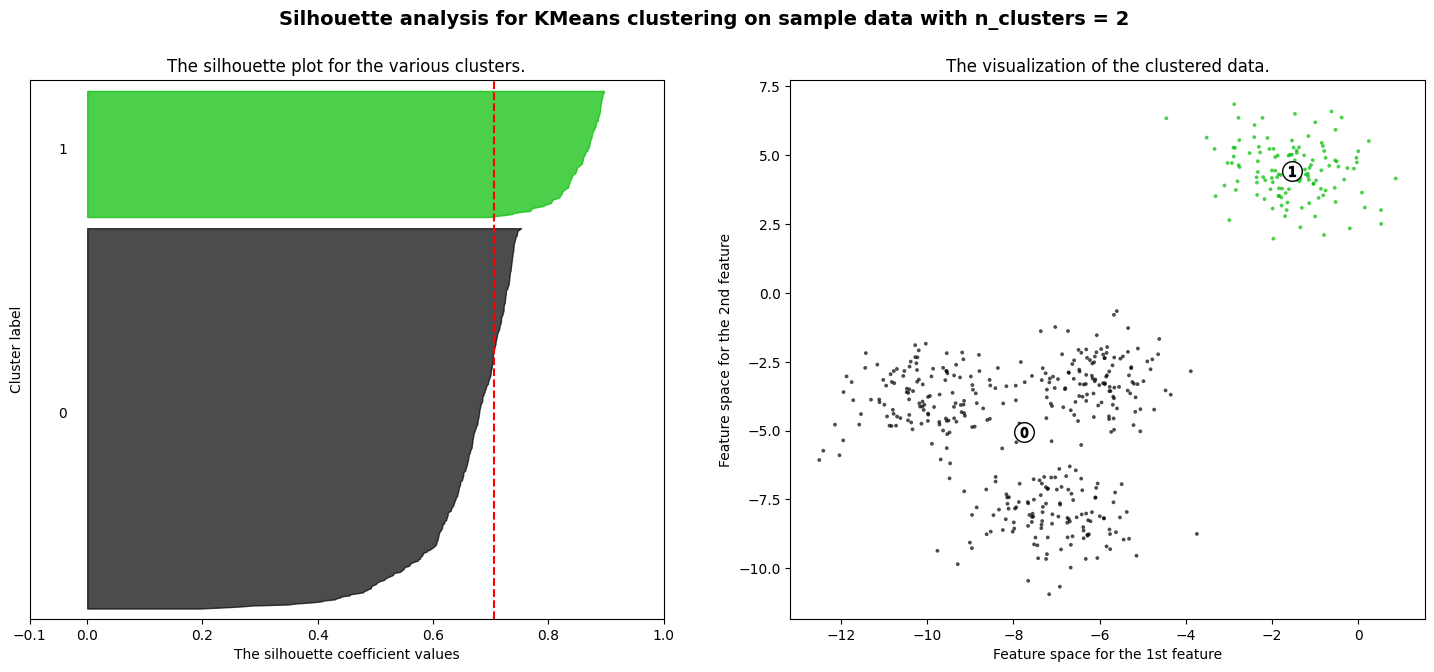

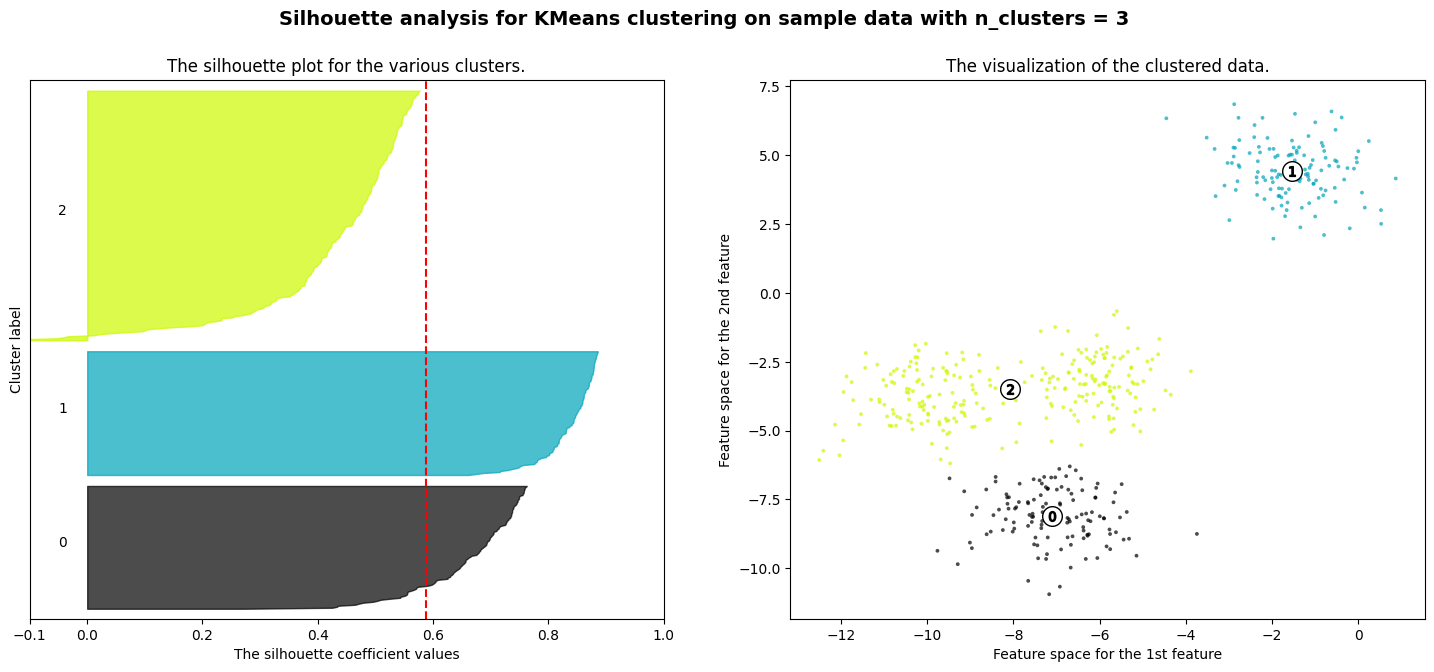

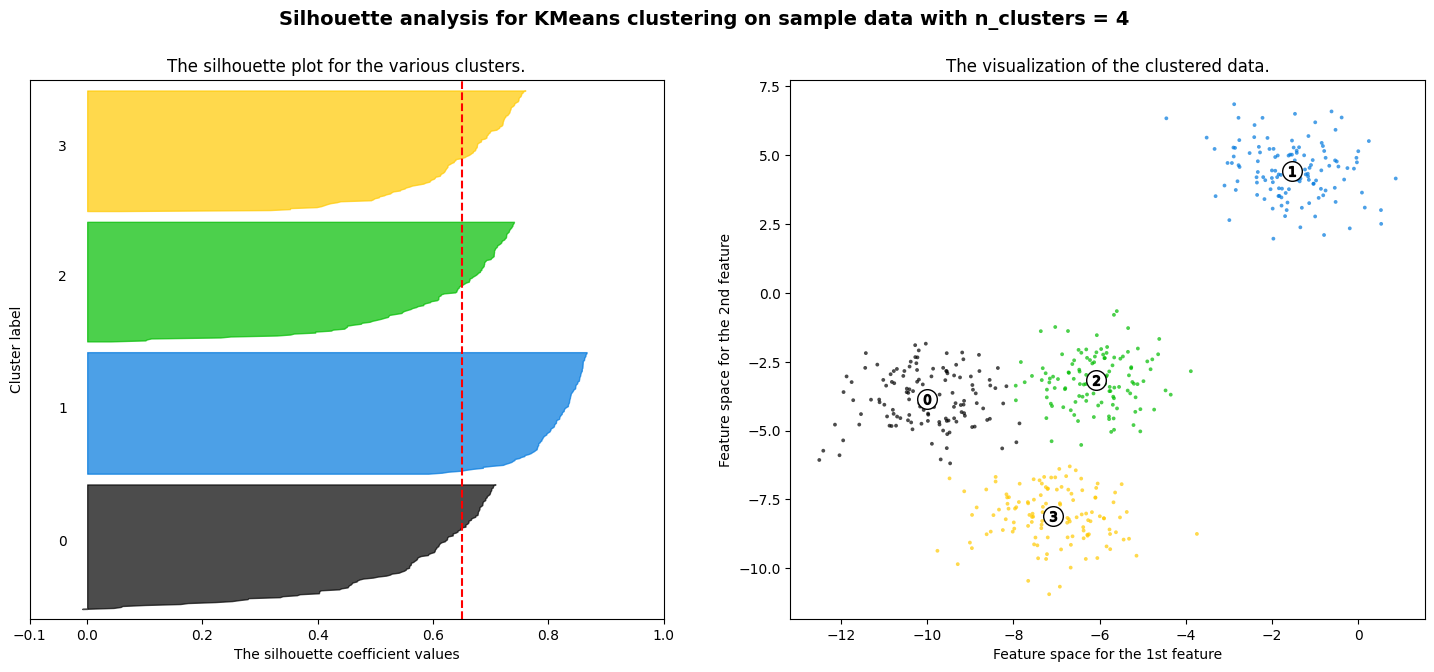

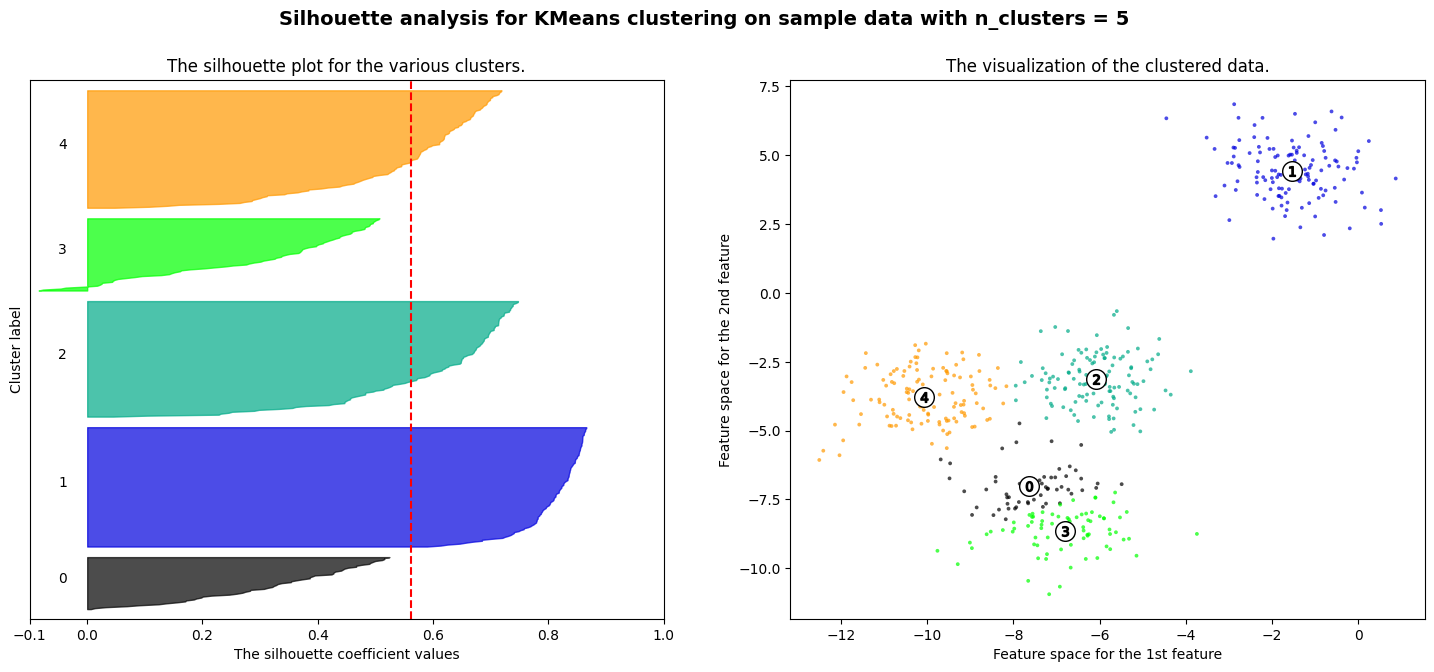

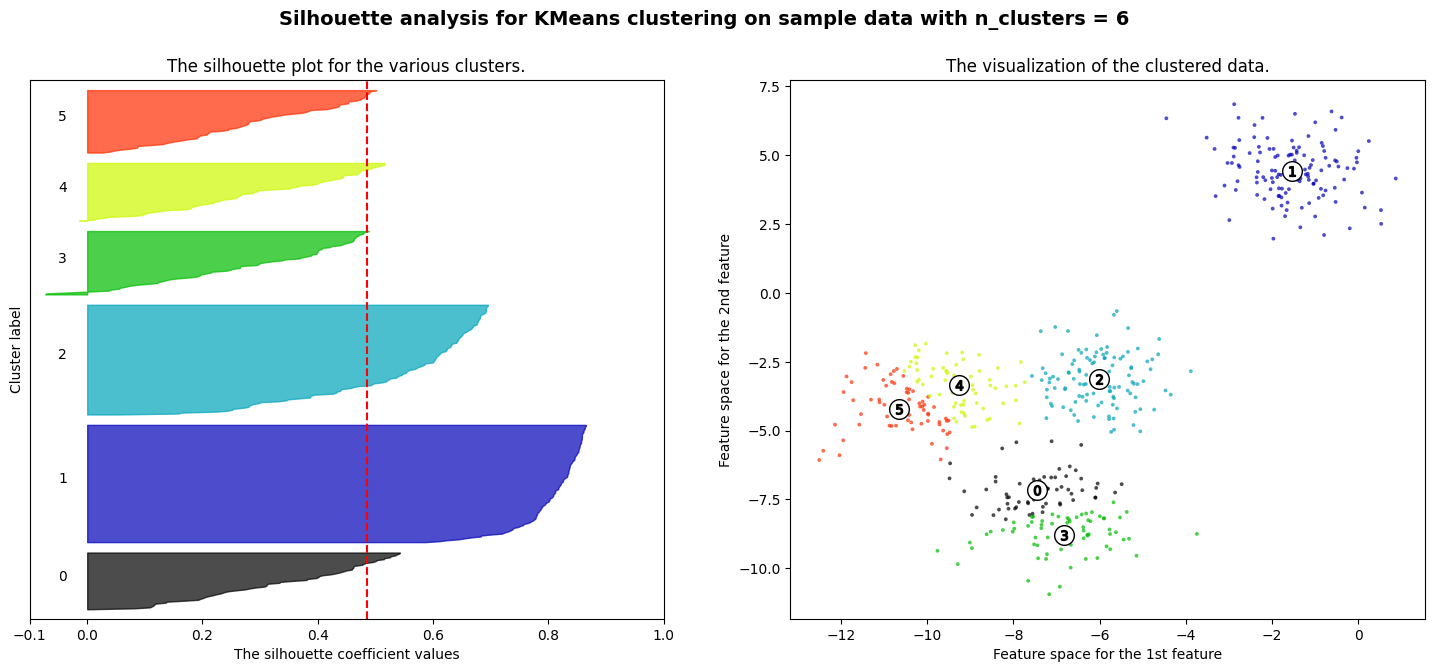

In [21]:
import matplotlib.cm as cm
import matplotlib.pyplot as plt
import numpy as np

from sklearn.cluster import KMeans
from sklearn.datasets import make_blobs
from sklearn.metrics import silhouette_samples, silhouette_score

# Generating the sample data from make_blobs
# This particular setting has one distinct cluster and 3 clusters placed close
# together.
X, y = make_blobs(
    n_samples=500,
    n_features=2,
    centers=4,
    cluster_std=1,
    center_box=(-10.0, 10.0),
    shuffle=True,
    random_state=1,
)  # For reproducibility

range_n_clusters = [2, 3, 4, 5, 6]

for n_clusters in range_n_clusters:
    # Create a subplot with 1 row and 2 columns
    fig, (ax1, ax2) = plt.subplots(1, 2)
    fig.set_size_inches(18, 7)

    # The 1st subplot is the silhouette plot
    # The silhouette coefficient can range from -1, 1 but in this example all
    # lie within [-0.1, 1]
    ax1.set_xlim([-0.1, 1])
    # The (n_clusters+1)*10 is for inserting blank space between silhouette
    # plots of individual clusters, to demarcate them clearly.
    ax1.set_ylim([0, len(X) + (n_clusters + 1) * 10])

    # Initialize the clusterer with n_clusters value and a random generator
    # seed of 10 for reproducibility.
    clusterer = KMeans(n_clusters=n_clusters, random_state=10)
    cluster_labels = clusterer.fit_predict(X)

    # The silhouette_score gives the average value for all the samples.
    # This gives a perspective into the density and separation of the formed
    # clusters
    silhouette_avg = silhouette_score(X, cluster_labels)
    print(
        "For n_clusters =",
        n_clusters,
        "The average silhouette_score is :",
        silhouette_avg,
    )

    # Compute the silhouette scores for each sample
    sample_silhouette_values = silhouette_samples(X, cluster_labels)

    y_lower = 10
    for i in range(n_clusters):
        # Aggregate the silhouette scores for samples belonging to
        # cluster i, and sort them
        ith_cluster_silhouette_values = sample_silhouette_values[cluster_labels == i]

        ith_cluster_silhouette_values.sort()

        size_cluster_i = ith_cluster_silhouette_values.shape[0]
        y_upper = y_lower + size_cluster_i

        color = cm.nipy_spectral(float(i) / n_clusters)
        ax1.fill_betweenx(
            np.arange(y_lower, y_upper),
            0,
            ith_cluster_silhouette_values,
            facecolor=color,
            edgecolor=color,
            alpha=0.7,
        )

        # Label the silhouette plots with their cluster numbers at the middle
        ax1.text(-0.05, y_lower + 0.5 * size_cluster_i, str(i))

        # Compute the new y_lower for next plot
        y_lower = y_upper + 10  # 10 for the 0 samples

    ax1.set_title("The silhouette plot for the various clusters.")
    ax1.set_xlabel("The silhouette coefficient values")
    ax1.set_ylabel("Cluster label")

    # The vertical line for average silhouette score of all the values
    ax1.axvline(x=silhouette_avg, color="red", linestyle="--")

    ax1.set_yticks([])  # Clear the yaxis labels / ticks
    ax1.set_xticks([-0.1, 0, 0.2, 0.4, 0.6, 0.8, 1])

    # 2nd Plot showing the actual clusters formed
    colors = cm.nipy_spectral(cluster_labels.astype(float) / n_clusters)
    ax2.scatter(
        X[:, 0], X[:, 1], marker=".", s=30, lw=0, alpha=0.7, c=colors, edgecolor="k"
    )

    # Labeling the clusters
    centers = clusterer.cluster_centers_
    # Draw white circles at cluster centers
    ax2.scatter(
        centers[:, 0],
        centers[:, 1],
        marker="o",
        c="white",
        alpha=1,
        s=200,
        edgecolor="k",
    )

    for i, c in enumerate(centers):
        ax2.scatter(c[0], c[1], marker="$%d$" % i, alpha=1, s=50, edgecolor="k")

    ax2.set_title("The visualization of the clustered data.")
    ax2.set_xlabel("Feature space for the 1st feature")
    ax2.set_ylabel("Feature space for the 2nd feature")

    plt.suptitle(
        "Silhouette analysis for KMeans clustering on sample data with n_clusters = %d"
        % n_clusters,
        fontsize=14,
        fontweight="bold",
    )

plt.show()



- **군집 개수 2개**: 평균 실루엣 계수(silhouette_score) 약 0.704로 매우 높게 나타남
  - 왼쪽 그림: 개별 군집에 속하는 데이터의 실루엣 계수를 2차원으로 나타냄. X축은 실루엣 계수 값, Y축은 개별 군집과 이에 속하는 데이터(군집은 Y축에 숫자 값 0, 1로 표시, Y축 높이로 데이터 수 추측 가능). 점선은 전체 평균 실루엣 계수 값
  - 1번 군집의 모든 데이터는 평균 실루엣 계수 값 이상이지만, 2번 군집의 경우는 평균보다 적은 데이터 값이 매우 많음
  - 오른쪽 그림: 1번 군집은 0번 군집과 멀리 떨어져 있고 내부 데이터끼리도 잘 뭉쳐 있음. 0번 군집은 내부 데이터끼리 많이 떨어져 있음
- **군집 개수 3개**: 전체 평균 실루엣 계수 값 약 0.588
  - 1번, 2번 군집은 평균보다 높은 실루엣 계수 값을 가지지만, 0번은 모두 평균보다 낮음
  - 0번은 내부 데이터 간 거리도 멀지만, 2번 군집과도 가깝게 위치하고 있기 때문
- **군집 개수 4개**: 평균 실루엣 계수 값 약 0.65
  - 개별 군집의 평균 실루엣 계수 값이 비교적 균일하게 위치
  - 1번 군집은 모든 데이터가 평균보다 높은 계수 값, 0번·2번은 절반 이상이 평균보다 높음, 3번은 약 1/3 정도가 평균보다 높음
  - 군집이 2개인 경우보다 평균 실루엣 계수 값이 작지만 4개인 경우가 가장 이상적인 군집화 개수로 판단 가능

- `visualize_silhouette()`: 군집 개수를 변화시키면서 K-평균 군집을 수행했을 때 개별 군집별 평균 실루엣 계수 값을 시각화해서 군집의 개수를 정하는 데 도움을 줌
  - 첫 번째 파라미터: 여러 개의 군집 개수를 리스트로 받음 / 두 번째 파라미터: 피처 데이터 세트
  - 피처 데이터 세트 X_features에 대해 군집이 2개, 3개, 4개, 5개일 때의 군집별 평균 실루엣 계수 값을 알고 싶다면 아래처럼 호출

In [22]:
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_samples, silhouette_score
import matplotlib.pyplot as plt
import matplotlib.cm as cm
import numpy as np

def visualize_silhouette(cluster_list, X):
    from matplotlib import pyplot as plt

    for n_clusters in cluster_list:
        fig, ax1 = plt.subplots(1)
        fig.set_size_inches(6, 4)

        ax1.set_xlim([-0.1, 1])
        ax1.set_ylim([0, len(X) + (n_clusters + 1) * 10])

        kmeans = KMeans(n_clusters=n_clusters, random_state=10)
        cluster_labels = kmeans.fit_predict(X)

        silhouette_vals = silhouette_samples(X, cluster_labels)
        silhouette_avg = silhouette_score(X, cluster_labels)

        y_lower = 10
        for i in range(n_clusters):
            ith_silhouette_vals = silhouette_vals[cluster_labels == i]
            ith_silhouette_vals.sort()

            size_cluster_i = ith_silhouette_vals.shape[0]
            y_upper = y_lower + size_cluster_i

            color = cm.nipy_spectral(float(i) / n_clusters)
            ax1.fill_betweenx(np.arange(y_lower, y_upper),
                              0, ith_silhouette_vals,
                              facecolor=color, edgecolor=color, alpha=0.7)

            ax1.text(-0.05, y_lower + 0.5 * size_cluster_i, str(i))
            y_lower = y_upper + 10

        ax1.axvline(x=silhouette_avg, color="red", linestyle="--")
        ax1.set_title(f"Silhouette plot for {n_clusters} clusters")
        ax1.set_xlabel("Silhouette coefficient values")
        ax1.set_ylabel("Cluster label")

        plt.tight_layout()
        plt.show()

In [ ]:
# visualize_silhouette([2, 3, 4, 5], X_features)

- 사이킷런 홈페이지 예와 비슷하게 make_blobs() 함수로 4개 군집 중심의 500개 2차원 데이터 세트를 만들고 K-평균으로 군집화할 때 2개, 3개, 4개, 5개 중 최적의 군집 개수를 시각화로 확인

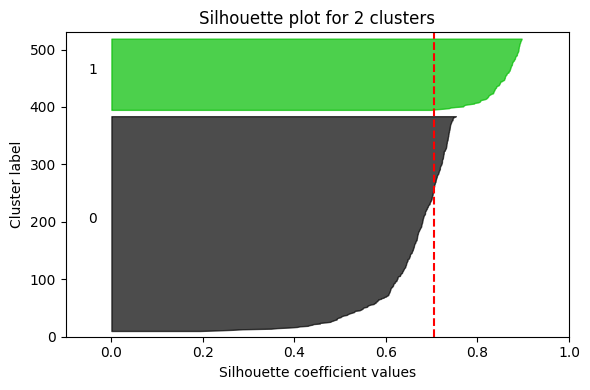

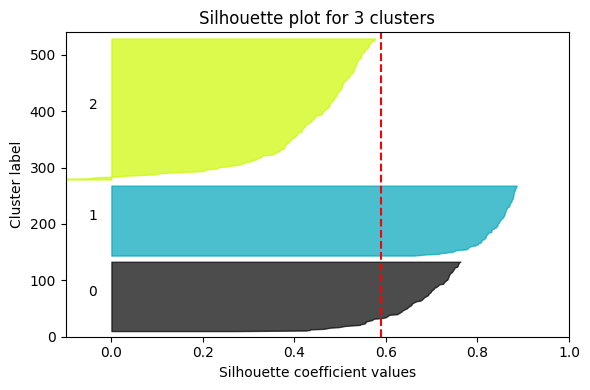

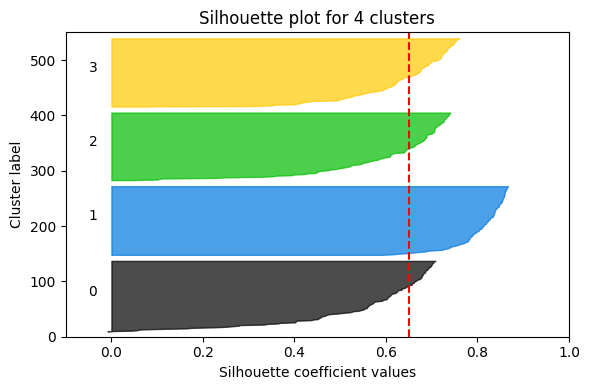

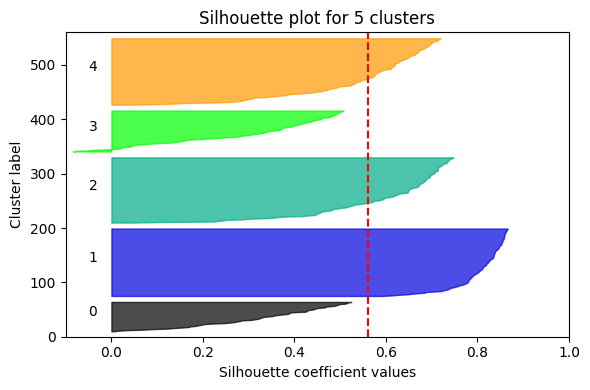

In [23]:
# make_blobs를 통해 군집화를 위한 4개의 군집 중심의 500개 2차원 데이터 세트 생성
from sklearn.datasets import make_blobs
X, y = make_blobs(n_samples=500, n_features=2, centers=4, cluster_std=1,
                  center_box=(-10.0, 10.0), shuffle=True, random_state=1)

# 군집 개수가 2개, 3개, 4개, 5개일 때의 군집별 실루엣 계수 평균값을 시각화
visualize_silhouette([ 2, 3, 4, 5], X)

- 앞에서 소개한 바와 마찬가지로 4개의 군집일 때 가장 최적이 됨 (2개 0.705 / 3개 0.588 / 4개 0.651 / 5개 0.575)
- 붓꽃 데이터를 이용해 K-평균 수행 시 최적의 군집 개수 확인

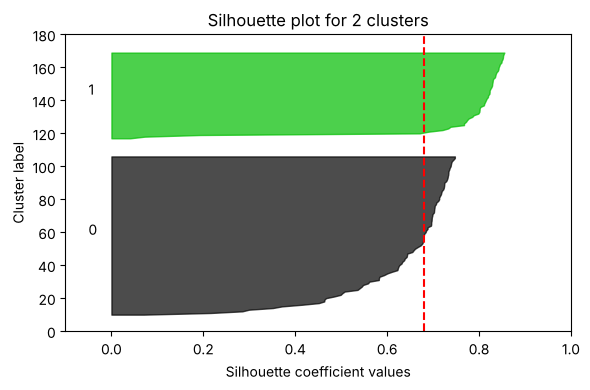

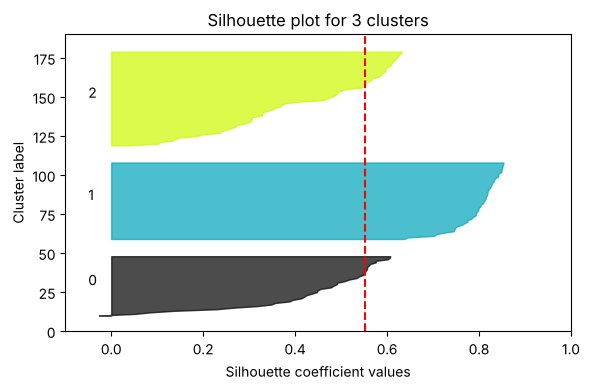

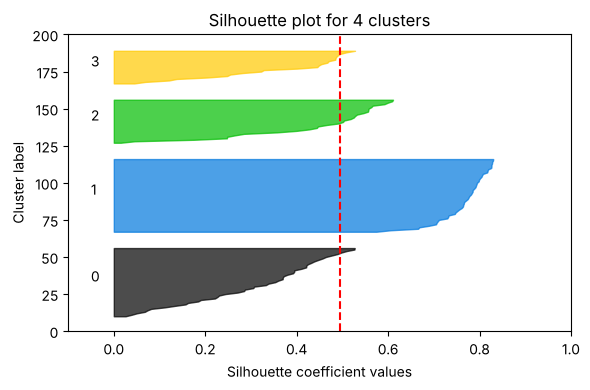

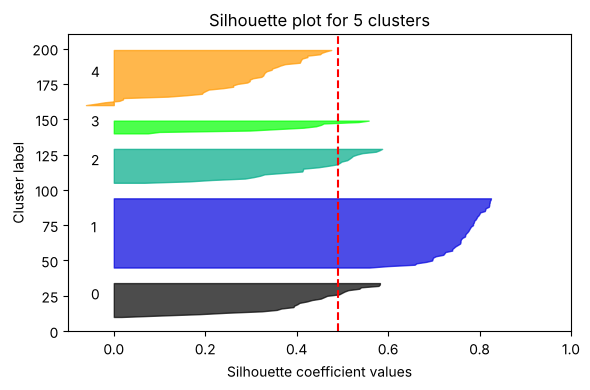

In [ ]:
from sklearn.datasets import load_iris
iris=load_iris()
visualize_silhouette([ 2, 3, 4, 5 ], iris.data)

- 붓꽃 데이터를 K-평균으로 군집화할 경우에는 군집 개수를 2개로 하는 것이 가장 좋아 보임 (책 그림: 2개 0.681 / 3개 0.553 / 4개 0.498 / 5개 0.493)
  - 3개의 경우 평균 실루엣 계수 값도 2개보다 작을뿐더러 1번 군집과 다른 0번, 2번 군집과의 실루엣 계수의 편차가 큼. 4개, 5개의 경우도 마찬가지
- 실루엣 계수를 통한 K-평균 군집 평가 방법은 직관적으로 이해하기 쉽지만, 각 데이터별로 다른 데이터와의 거리를 반복적으로 계산해야 하므로 데이터양이 늘어나면 수행 시간이 크게 늘어남
- 특히 몇 만 건 이상의 데이터에 대해 사이킷런의 실루엣 계수 평가 API를 개인용 PC에서 수행할 경우 메모리 부족 등의 에러가 발생하기 쉬움 → 군집별로 임의의 데이터를 샘플링해 실루엣 계수를 평가하는 방안을 고민해야 함

## 03 평균 이동

### 평균 이동(Mean Shift)의 개요

- 평균 이동(Mean Shift)은 K-평균과 유사하게 중심을 군집의 중심으로 지속적으로 움직이면서 군집화 수행
- 하지만 K-평균이 중심에 소속된 데이터의 평균 거리 중심으로 이동하는 데 반해, 평균 이동은 중심을 **데이터가 모여 있는 밀도가 가장 높은 곳**으로 이동시킴
- 평균 이동 군집화는 데이터의 분포도를 이용해 군집 중심점을 찾음
  - 군집 중심점은 데이터 포인트가 모여있는 곳이라는 생각에서 착안 → 확률 밀도 함수(probability density function) 이용
  - 가장 집중적으로 데이터가 모여있어 확률 밀도 함수가 피크인 점을 군집 중심점으로 선정
  - 일반적으로 주어진 모델의 확률 밀도 함수를 찾기 위해 KDE(Kernel Density Estimation) 이용
- 특정 데이터를 반경 내의 데이터 분포 확률 밀도가 가장 높은 곳으로 이동하기 위해 주변 데이터와의 거리 값을 KDE 함수 값으로 입력한 뒤 그 반환 값을 현재 위치에서 업데이트하면서 이동 → 이를 전체 데이터에 반복 적용하면서 군집 중심점을 찾아냄

**평균 이동 수행 과정**
1. 개별 데이터의 특정 반경 내에 주변 데이터를 포함한 데이터 분포도를 KDE 기반의 Mean Shift 알고리즘으로 계산
2. KDE로 계산된 데이터 분포도가 높은 방향으로 데이터 이동
3. 모든 데이터를 1~2까지 수행하면서 데이터를 이동. 개별 데이터들이 군집중심점으로 모임
4. 지정된 반복(Iteration) 횟수만큼 전체 데이터에 대해서 KDE 기반으로 데이터를 이동시키면서 군집화 수행
5. 개별 데이터들이 모인 중심점을 군집 중심점으로 설정

**KDE(Kernel Density Estimation)**
- 커널(Kernel) 함수를 통해 어떤 변수의 확률 밀도 함수를 추정하는 대표적인 방법
- 관측된 데이터 각각에 커널 함수를 적용한 값을 모두 더한 뒤 데이터 건수로 나눠 확률 밀도 함수 추정
- 확률 밀도 함수 PDF(Probability Density Function): 확률 변수의 분포를 나타내는 함수. 정규분포 함수를 포함해 감마 분포, t-분포 등이 있음
  - 확률 밀도 함수를 알면 특정 변수가 어떤 값을 갖게 될지에 대한 확률을 알게 되므로, 변수의 특성(정규 분포의 경우 평균, 분산), 확률 분포 등 변수의 많은 요소를 알 수 있음
- 대표적인 커널 함수로 가우시안 분포 함수 사용
- KDE 커널 함수식 (K: 커널 함수, x: 확률 변숫값, x<sub>i</sub>: 관측값, h: 대역폭(bandwidth))

$$ KDE = \frac{1}{n}\sum_{i=1}^{n}K_h(x - x_i) = \frac{1}{nh}\sum_{i=1}^{n}K\left(\frac{x - x_i}{h}\right) $$

**대역폭 h**
- KDE 형태를 부드러운(또는 뾰족한) 형태로 평활화(Smoothing)하는 데 적용되며, h를 어떻게 설정하느냐에 따라 확률 밀도 추정 성능을 크게 좌우할 수 있음
- 일반적으로 평균 이동 군집화는 대역폭이 클수록 평활화된 KDE로 인해 적은 수의 군집 중심점을 가지며, 대역폭이 적을수록 많은 수의 군집 중심점을 가짐
- 평균 이동 군집화는 군집의 개수를 지정하지 않으며, 오직 대역폭의 크기에 따라 군집화 수행
- 사이킷런은 평균 이동 군집화를 위해 `MeanShift` 클래스 제공. 가장 중요한 초기화 파라미터는 `bandwidth`이며 KDE의 대역폭 h와 동일함
- 대역폭 크기 설정이 군집화 품질에 큰 영향을 미치므로 사이킷런은 최적의 대역폭 계산을 위해 `estimate_bandwidth()` 함수 제공
- make_blobs()의 cluster_std를 0.7로 정한 3개 군집의 데이터에 대해 bandwidth를 0.8로 설정한 평균 이동 군집화 적용

In [24]:
import numpy as np
from sklearn.datasets import make_blobs
from sklearn.cluster import MeanShift

X, y = make_blobs(n_samples=200, n_features=2, centers=3, cluster_std=0.7, random_state=0)

meanshift= MeanShift(bandwidth=0.8)
cluster_labels = meanshift.fit_predict(X)
print('cluster labels 유형:', np.unique(cluster_labels))

cluster labels 유형: [0 1 2 3 4 5]


- 군집이 0부터 5까지 6개로 분류됨 → 지나치게 세분화돼 군집화됨
- 일반적으로 bandwidth 값을 작게 할수록 군집 개수가 많아짐. bandwidth를 살짝 높인 1.0으로 MeanShift 수행

In [25]:
meanshift= MeanShift(bandwidth=1)
cluster_labels = meanshift.fit_predict(X)
print('cluster labels 유형:', np.unique(cluster_labels))

cluster labels 유형: [0 1 2]


- 3개의 군집으로 잘 군집화됨. 데이터의 분포 유형에 따라 bandwidth 값의 변화는 군집화 개수에 큰 영향을 미칠 수 있음 → MeanShift에서는 bandwidth를 최적화 값으로 설정하는 것이 매우 중요
- 사이킷런은 최적화된 bandwidth 값을 찾기 위해 `estimate_bandwidth()` 함수 제공. 파라미터로 피처 데이터 세트를 입력하면 최적화된 bandwidth 값 반환

In [26]:
from sklearn.cluster import estimate_bandwidth

bandwidth = estimate_bandwidth(X)
print('bandwidth 값:', round(bandwidth,3))

bandwidth 값: 1.816


- estimate_bandwidth()로 측정된 bandwidth를 평균 이동 입력값으로 적용해 동일한 make_blobs() 데이터 세트에 군집화 수행

In [27]:
import pandas as pd

clusterDF = pd.DataFrame(data=X, columns=['ftr1', 'ftr2'])
clusterDF['target'] = y

# estimate_bandwidth()로 최적의 bandwidth 계산
best_bandwidth = estimate_bandwidth(X)

meanshift= MeanShift(bandwidth=best_bandwidth)
cluster_labels = meanshift.fit_predict(X)
print('cluster labels 유형:',np.unique(cluster_labels))

cluster labels 유형: [0 1 2]


- 3개의 군집으로 구성됨. 평균 이동도 K-평균과 유사하게 중심을 가지고 있으므로 `cluster_centers_` 속성으로 군집 중심 좌표 표시 가능

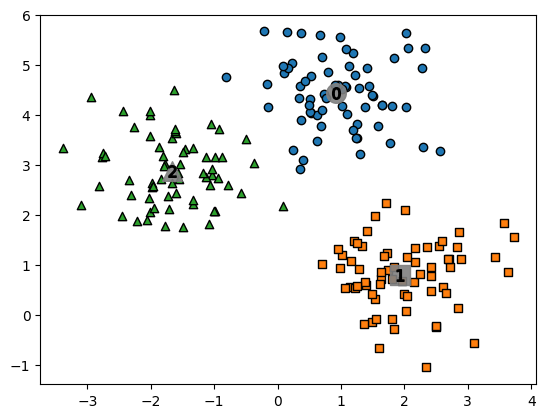

In [28]:
import matplotlib.pyplot as plt
%matplotlib inline

clusterDF['meanshift_label']  = cluster_labels
centers = meanshift.cluster_centers_
unique_labels = np.unique(cluster_labels)
markers=['o', 's', '^', 'x', '*']

for label in unique_labels:
    label_cluster = clusterDF[clusterDF['meanshift_label']==label]
    center_x_y = centers[label]
    # 군집별로 다른 마커로 산점도 적용
    plt.scatter(x=label_cluster['ftr1'], y=label_cluster['ftr2'], edgecolor='k', marker=markers[label])

    # 군집별 중심 표현
    plt.scatter(x=center_x_y[0], y=center_x_y[1], s=200, color='gray', alpha=0.9,
marker=markers[label])
    plt.scatter(x=center_x_y[0], y=center_x_y[1], s=70, color='k', edgecolor='k', marker='$%d$' % label)

plt.show()

- target 값과 군집 label 값 비교 → Target 값과 군집 label 값이 1:1로 잘 매칭됨

In [29]:
print(clusterDF.groupby('target')['meanshift_label'].value_counts())

target  meanshift_label
0       0                  67
1       1                  67
2       2                  66
Name: count, dtype: int64


- **평균 이동의 장점**
  - 데이터 세트의 형태를 특정 형태로 가정한다든가, 특정 분포도 기반의 모델로 가정하지 않기 때문에 좀 더 유연한 군집화 가능
  - 이상치의 영향력도 크지 않으며, 미리 군집의 개수를 정할 필요도 없음
- **평균 이동의 단점**: 알고리즘의 수행 시간이 오래 걸리고 무엇보다도 band-width의 크기에 따른 군집화 영향도가 매우 큼
- 일반적으로 평균 이동 군집화 기법은 분석 업무 기반의 데이터 세트보다는 컴퓨터 비전 영역에서 더 많이 사용됨. 이미지나 영상 데이터에서 특정 개체를 구분하거나 움직임을 추적하는 데 뛰어난 역할을 수행하는 알고리즘임

## 04 GMM(Gaussian Mixture Model)

### GMM(Gaussian Mixture Model) 소개

- GMM 군집화: 군집화를 적용하고자 하는 데이터가 여러 개의 가우시안 분포(GaussianDistribution)를 가진 데이터 집합들이 섞여서 생성된 것이라는 가정하에 군집화를 수행하는 방식
- 가우시안 분포: 정규 분포(Normal distribution)로도 알려짐. 좌우 대칭형의 종(Bell) 형태를 가진 통계학에서 가장 잘 알려진 연속 확률 함수
  - 평균 μ를 중심으로 높은 데이터 분포도를 가짐
  - 좌우 표준편차 1에 전체 데이터의 68.27%, 좌우 표준편차 2에 전체 데이터의 95.45%를 가짐
  - 평균이 0이고, 표준편차가 1인 정규 분포를 표준 정규 분포라고 함
- GMM은 데이터를 여러 개의 가우시안 분포가 섞인 것으로 간주하고, 섞인 데이터 분포에서 개별 유형의 가우시안 분포를 추출함
- 예시 : 세 개의 가우시안 분포 A, B, C를 가진 데이터 세트 → 세 정규 분포를 합치면 정규 분포 A+B+C 형태가 됨
  - 군집화를 수행하려는 실제 데이터 세트의 분포도가 이와 같다면 정규 분포 A, B, C가 합쳐서 된 데이터 분포도임을 알 수 있음
- 전체 데이터 세트는 서로 다른 정규 분포 형태를 가진 여러 가지 확률 분포 곡선으로 구성될 수 있으며, 이러한 서로 다른 정규 분포에 기반해 군집화를 수행하는 것이 GMM 군집화 방식
  - 가령 1000개의 데이터 세트가 있다면 이를 구성하는 여러 개의 정규 분포 곡선을 추출하고, 개별 데이터가 이 중 어떤 정규 분포에 속하는지 결정하는 방식
- 이와 같은 방식을 GMM에서는 **모수 추정**이라고 하며, 대표적으로 2가지를 추정함
  - 개별 정규 분포의 평균과 분산
  - 각 데이터가 어떤 정규 분포에 해당되는지의 확률
- 모수 추정을 위해 GMM은 **EM(Expectation and Maximization)** 방법 적용
- 사이킷런은 GMM의 EM 방식을 통한 모수 추정 군집화를 지원하기 위해 `GaussianMixture` 클래스 지원

### GMM을 이용한 붓꽃 데이터 세트 군집화

- GMM은 확률 기반 군집화이고 K-평균은 거리 기반 군집화임
- 붓꽃 데이터 세트로 두 가지 방식의 군집화를 수행한 뒤 비교

In [30]:
from sklearn.datasets import load_iris
from sklearn.cluster import KMeans

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
%matplotlib inline

iris = load_iris()
feature_names = ['sepal_length', 'sepal_width', 'petal_length', 'petal_width']

# 좀 더 편리한 데이터 Handling을 위해 DataFrame으로 변환
irisDF = pd.DataFrame(data=iris.data, columns=feature_names)
irisDF['target'] = iris.target

- GaussianMixture 객체의 가장 중요한 초기화 파라미터는 `n_components` = gaussian mixture의 모델의 총 개수
  - K-평균의 n_clusters와 같이 군집의 개수를 정하는 데 중요한 역할
- n_components를 3으로 설정하고 GaussianMixture로 군집화 수행
- `fit(피처 데이터 세트)`와 `predict(피처 데이터 세트)`를 수행해 군집을 결정한 뒤 irisDF의 'gmm_cluster' 칼럼명으로 저장하고 타깃별로 군집 매핑 확인

In [ ]:
from sklearn.mixture import GaussianMixture

gmm = GaussianMixture(n_components=3, random_state=0).fit(iris.data)
gmm_cluster_labels = gmm.predict(iris.data)

# 군집화 결과를 irisDF의 'gmm_cluster' 칼럼명으로 저장
irisDF['gmm_cluster'] = gmm_cluster_labels
irisDF['target'] = iris.target

# target 값에 따라 gmm_cluster 값이 어떻게 매핑됐는지 확인.
iris_result = irisDF.groupby(['target'])['gmm_cluster'].value_counts()
print(iris_result)

target  gmm_cluster
0       1              50
1       0              45
        2               5
2       2              50
Name: count, dtype: int64


- Target 0은 cluster 0으로, Target 2는 cluster 1로 모두 잘 매핑됨
- Target 1만 cluster 2로 45개(90%), cluster 1로 5개(10%) 매핑됨
- 앞 절의 붓꽃 데이터 세트의 K-평균 군집화 결과보다 더 효과적인 분류 결과가 도출됨
- 붓꽃 데이터 세트의 K-평균 군집화 수행 결과 확인

In [31]:
kmeans = KMeans(n_clusters=3, init='k-means++', max_iter=300, random_state=0).fit(iris.data)
kmeans_cluster_labels = kmeans.predict(iris.data)
irisDF['kmeans_cluster'] = kmeans_cluster_labels
iris_result = irisDF.groupby(['target'])['kmeans_cluster'].value_counts()
print(iris_result)

target  kmeans_cluster
0       1                 50
1       0                 47
        2                  3
2       2                 36
        0                 14
Name: count, dtype: int64


- 이는 어떤 알고리즘에 더 뛰어나다는 의미가 아니라 붓꽃 데이터 세트가 GMM 군집화에 더 효과적이라는 의미임
- K-평균은 평균 거리 중심으로 중심을 이동하면서 군집화를 수행하는 방식이므로 개별 군집 내의 데이터가 원형으로 흩어져 있는 경우에 매우 효과적으로 군집화 수행 가능

### GMM과 K-평균의 비교

- KMeans는 원형의 범위에서 군집화 수행. 데이터 세트가 원형의 범위를 가질수록 KMeans의 군집화 효율은 더욱 높아짐
- KMeans 군집화는 개별 군집의 중심에서 원형의 범위로 데이터를 군집화함
- 데이터가 원형의 범위로 퍼져 있지 않은 경우 → KMeans는 대표적으로 데이터가 길쭉한 타원형으로 늘어선 경우에 군집화를 잘 수행하지 못함
- 해당 데이터 세트를 make_blobs()의 데이터를 변환해 만들어봄
- 군집을 자주 시각화하므로 별도의 함수 `visualize_cluster_plot(clusterobj, dataframe, label_name, iscluster=True)`를 만들어 이용. 앞에서 많이 사용된 예제 코드 로직을 함수로 만든 것이므로 책에는 기술하지 않고 부록으로 제공되는 소스 코드에만 수록됨
- `visualize_cluster_plot()` 함수 인자
  - `clusterobj`: 사이킷런의 군집 수행 객체. KMeans나 GaussianMixture의 fit()와 predict()로 군집화를 완료한 객체. 만약 군집화 결과 시각화가 아니고 make_blobs()로 생성한 데이터의 시각화일 경우 None 입력
  - `dataframe`: 피처 데이터 세트와 label 값을 가진 DataFrame
  - `label_name`: 군집화 결과 시각화일 경우 dataframe 내의 군집화 label 칼럼명, make_blobs() 결과 시각화일 경우는 dataframe 내의 target 칼럼명
  - `iscenter`: 사이킷런 Cluster 객체가 군집 중심 좌표를 제공하면 True, 그렇지 않으면 False

In [32]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.datasets import make_blobs
%matplotlib inline

def visualize_cluster_plot(cluster_result=None, dataframe=None, label_name='target', iscenter=True):
    if dataframe is None:
        print("Error: DataFrame is required.")
        return

    unique_labels = np.unique(dataframe[label_name])
    markers = ['o', 's', '^', 'x', '*', 'D', '+', 'v', '<', '>']

    for label in unique_labels:
        label_cluster = dataframe[dataframe[label_name] == label]
        plt.scatter(x=label_cluster['ftr1'], y=label_cluster['ftr2'], edgecolor='k',
                    marker=markers[label % len(markers)])

        if iscenter and cluster_result is not None and hasattr(cluster_result, 'cluster_centers_'):
            # Assuming cluster_result has a .cluster_centers_ attribute
            center_x_y = cluster_result.cluster_centers_[label]
            plt.scatter(x=center_x_y[0], y=center_x_y[1], s=200, color='gray', alpha=0.9,
                        marker=markers[label % len(markers)])
            plt.scatter(x=center_x_y[0], y=center_x_y[1], s=70, color='k', edgecolor='k',
                        marker='$%d$' % label)
    plt.show()

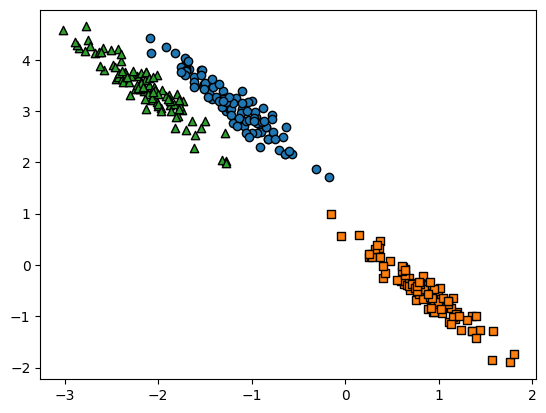

In [33]:
from sklearn.datasets import make_blobs

# make_blobs()로 300개의 데이터 세트, 3개의 군집 세트, cluster_std=0.5를 만듦.
X, y = make_blobs(n_samples=300, n_features=2, centers=3, cluster_std=0.5, random_state=0)

# 길게 늘어난 타원형의 데이터 세트를 생성하기 위해 변환함.
transformation = [[0.60834549, -0.63667341], [-0.40887718, 0.85253229]]
X_aniso = np.dot(X, transformation)
# feature 데이터 세트와 make_blobs( )의 y 결괏값을 DataFrame으로 저장
clusterDF = pd.DataFrame(data=X_aniso, columns=['ftr1', 'ftr2'])
clusterDF['target'] = y
# 생성된 데이터 세트를 target별로 다른 마커로 표시해 시각화함
visualize_cluster_plot(None, clusterDF, 'target', iscenter=False)

- 위와 같이 만들어진 데이터 세트에서는 KMeans의 군집화 정확성이 떨어지게 됨. KMeans가 위 데이터 세트를 어떻게 군집화하는지 확인

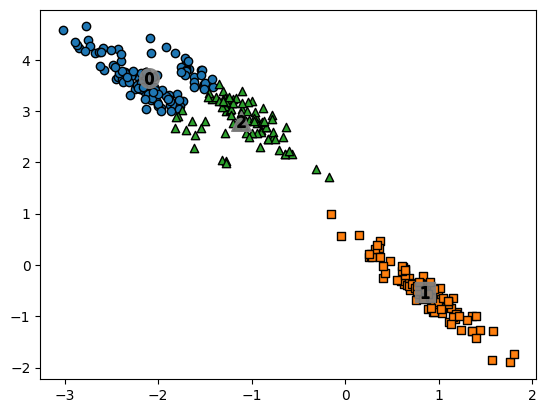

In [35]:
# 3개의 군집 기반 Kmeans를 X_aniso 데이터 세트에 적용
kmeans = KMeans(3, random_state=0)
kmeans_label = kmeans.fit_predict(X_aniso)
clusterDF['kmeans_label'] = kmeans_label

visualize_cluster_plot(kmeans, clusterDF, 'kmeans_label', iscenter=True)

- KMeans로 군집화를 수행할 경우, 주로 원형 영역 위치로 개별 군집화가 되면서 원하는 방향으로 구성되지 않음
- KMeans가 평균 거리 기반으로 군집화를 수행하므로 같은 거리상 원형으로 군집을 구성하면서 위와 같이 길쭉한 방향으로 데이터가 밀접해 있을 경우에는 최적의 군집화가 어려움
- GMM으로 군집화 수행

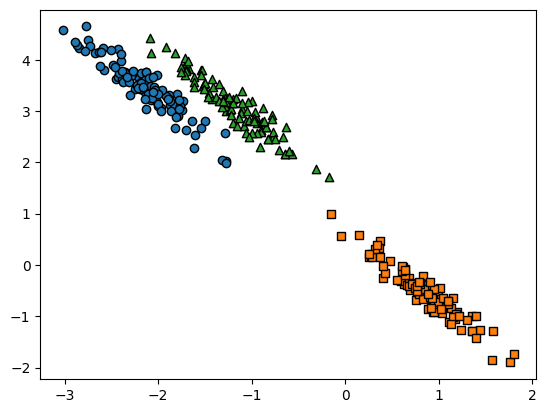

In [38]:
# 3개의 n_components 기반 GMM을 X_aniso 데이터 세트에 적용

from sklearn.mixture import GaussianMixture
gmm = GaussianMixture(n_components=3, random_state=0)
gmm_label = gmm.fit(X_aniso).predict(X_aniso)
clusterDF['gmm_label'] = gmm_label

# GaussianMixture는 cluster_centers_ 속성이 없으므로 iscenter를 False로 설정.
visualize_cluster_plot(gmm, clusterDF, 'gmm_label', iscenter=False)

- 데이터가 분포된 방향에 따라 정확하게 군집화됨
- GMM은 K-평균과 다르게 군집의 중심 좌표를 구할 수 없기 때문에 군집 중심 표현이 visualize_cluster_plot()에서 시각화되지 않음
- make_blobs()의 target 값과 KMeans, GMM의 군집 Label 값을 서로 비교해 군집화 효율 차이 확인

In [39]:
print('### KMeans Clustering ###')
print(clusterDF.groupby('target')['kmeans_label'].value_counts())
print('\n### Gaussian Mixture Clustering ###')
print(clusterDF.groupby('target')['gmm_label'].value_counts())

### KMeans Clustering ###
target  kmeans_label
0       2                73
        0                27
1       1               100
2       0                86
        2                14
Name: count, dtype: int64

### Gaussian Mixture Clustering ###
target  gmm_label
0       2            100
1       1            100
2       0            100
Name: count, dtype: int64


- KMeans의 경우 군집 1번만 정확히 매핑됐지만, 나머지 군집의 경우 target 값과 어긋나는 경우가 발생
- GMM의 경우는 군집이 target 값과 잘 매핑됨
- 이처럼 GMM은 KMeans보다 유연하게 다양한 데이터 세트에 잘 적용될 수 있다는 장점이 있음. 하지만 군집화를 위한 수행 시간이 오래 걸린다는 단점이 있음